### Setting up the connection with the Database

In [3]:
import os
from pathlib import Path
if Path.cwd().name == "Analysis":
    os.chdir("..")

In [4]:

import duckdb
con = duckdb.connect("ocean.duckdb", read_only=True)

In [5]:
con.sql("SHOW TABLES").df()

,name
0,bloom_events
1,bloom_frequency
2,chl_abs_exceed
3,chl_daily_model
4,chl_dineof
5,chl_erd
6,chl_model
7,chl_pixel_clim
8,cuti
9,cuti_average


#### Loading in the data table that will be used for the modeling for Kelp

In [6]:
long_model =  con.execute("SELECT * FROM 'model_long'").df()
light_model =  con.execute("SELECT * FROM 'light_model'").df()
kelp_waves_depth = con.execute("SELECT * FROM 'kelp_waves_depth'").df()
kelp_hinges= con.execute("SELECT * FROM 'kelp_hinges'").df()

In [7]:
long_model

,quarter,kelp_biomass,avg_sst,avg_pdo,avg_cuti
0,2008-01-01,39.013001,13.097624,-1.183333,0.739013
1,2008-04-01,326.425187,14.153249,-1.546667,0.770022
2,2008-07-01,816.896073,18.691596,-1.313333,0.460989
3,2008-10-01,498.031191,16.084681,-1.020000,0.345978
4,2009-01-01,402.809243,13.482346,-1.576667,0.243500
...,...,...,...,...,...
68,2025-01-01,61.866007,13.362018,-0.993333,0.758933
69,2025-04-01,271.534719,15.265020,-1.843333,0.995242
70,2025-07-01,237.894648,18.882433,-2.693333,0.508391
71,2025-10-01,66.457176,17.591676,-1.076667,0.437870


In [8]:
light_model

,quarter,kelp_biomass,avg_sst,avg_pdo,avg_cuti,avg_kdpar
0,2012-01-01,148.322895,13.384606,-1.333333,0.392703,0.188747
1,2012-04-01,265.847722,14.546735,-1.213333,0.863879,0.270910
2,2012-07-01,206.135882,18.378599,-2.093333,0.488641,0.190725
3,2012-10-01,66.651176,17.114493,-0.473333,0.214837,0.171767
4,2013-01-01,231.256725,13.451281,-0.940000,0.236978,0.208366
5,2013-04-01,784.832022,15.369779,-0.666667,0.902044,0.273233
6,2013-07-01,575.875745,17.637971,-0.813333,0.625033,0.205436
7,2013-10-01,272.095835,16.524491,-0.800000,-0.039272,0.174809
8,2014-01-01,90.906987,14.861365,0.140000,-0.038111,0.176363
9,2014-04-01,205.068075,15.605808,0.633333,0.643242,0.233228


In [9]:
kelp_waves_depth

,lat,lat_band,lon,lon_band,elevation_m,quarter,kelp_biomass,kelp_area,sst_c,sst_quarter_lag,sst_anom_quarter_lag,avg_cuti,cuti_quarter_lag,avg_wave_height_m,max_wave_height_m,wave_max_lag,waves_quarter_lag,mean_pdo,pdo_quarter_lag
0,34.101043,682.0,-120.517883,-2411.0,-63.259403,2008-01-01,0.0,0.0,12.412837,NaN,NaN,0.739013,NaN,2.442391,8.84,NaN,NaN,-1.183333,-0.976667
1,34.101043,682.0,-120.517883,-2411.0,-63.259403,2008-04-01,4560.0,657.0,12.369462,12.412837,-0.510678,0.770022,0.739013,1.867674,4.70,8.84,2.442391,-1.546667,-1.183333
2,34.101043,682.0,-120.517883,-2411.0,-63.259403,2008-07-01,0.0,0.0,16.744123,12.369462,-0.619517,0.460989,0.770022,1.576353,3.19,4.70,1.867674,-1.313333,-1.546667
3,34.101043,682.0,-120.517883,-2411.0,-63.259403,2008-10-01,0.0,0.0,15.138735,16.744123,0.799257,0.345978,0.460989,2.002870,4.56,3.19,1.576353,-1.020000,-1.313333
4,34.101043,682.0,-120.517883,-2411.0,-63.259403,2009-01-01,0.0,0.0,13.050300,15.138735,-0.190096,0.243500,0.345978,2.005928,4.60,4.56,2.002870,-1.576667,-1.020000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8230423,34.048405,680.0,-119.727592,-2395.0,-6.319315,2024-07-01,0.0,0.0,NaN,NaN,NaN,0.593522,0.762791,1.609132,2.87,5.26,2.006216,-2.696667,-2.643333
8230424,34.048412,680.0,-119.727267,-2395.0,-6.319315,2023-04-01,0.0,0.0,NaN,NaN,NaN,0.815187,0.025644,1.756041,4.38,8.61,2.642912,-2.753333,-1.843333
8230425,34.048405,680.0,-119.727592,-2395.0,-6.319315,2023-04-01,0.0,0.0,NaN,NaN,NaN,0.815187,0.025644,1.756041,4.38,8.61,2.642912,-2.753333,-1.843333
8230426,34.048412,680.0,-119.727267,-2395.0,-6.319315,2014-01-01,0.0,0.0,NaN,NaN,NaN,-0.038111,-0.039272,2.177501,4.62,4.10,1.436298,0.140000,-0.800000


In [10]:
kelp_hinges

,quarter,kelp_islands,kelp_mainland,kelp_pooled,sst_islands,sst_mainland,wave_max,wave_h
0,2012-01-01,113.039144,258.640447,148.322895,13.018307,13.089232,6.09,0.0
1,2013-01-01,168.554006,427.216387,231.256725,13.110245,13.159797,4.04,0.0
2,2013-10-01,124.296875,734.010756,272.095835,16.034954,16.024851,4.10,0.0
3,2015-07-01,348.318809,406.133118,362.346145,19.725055,19.723805,2.82,0.0
4,2018-10-01,9.680279,9.101146,9.539893,17.226894,17.437802,6.65,0.0
...,...,...,...,...,...,...,...,...
69,2017-04-01,267.438561,419.084270,304.203512,14.096264,13.838807,4.99,0.0
70,2017-10-01,70.393432,80.578984,72.862482,16.621289,16.653469,5.08,0.0
71,2018-07-01,229.963693,451.974519,283.797629,19.069302,19.262153,3.06,0.0
72,2019-10-01,48.323400,18.831460,41.174345,16.161483,16.422879,5.19,0.0


---


### Linear model Set Up


### Importing libraries

In [11]:
# Data Handling
import pandas as pd
import numpy as np

# Data Access (APIs)
import requests
import json

# Oceanographic Data
import xarray as xr



# Statistics
from scipy import stats

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
    )

# Utiltities
from pathlib import Path
from datetime import datetime

In [12]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Long model
Setting up the long model that includes Sea Surface Temperatures, PDO, which is predicting kelp

Set Up

In [13]:
x = long_model[
    ["avg_sst",
     "avg_pdo", 
     "avg_cuti"]
]

y =long_model["kelp_biomass"]

Test, train, split the data

In [14]:
long_model["q"] = long_model.quarter.dt.quarter # accounts for seasonality
train = long_model[long_model.quarter < "2020-01-01"] # for time series its better to calculate the model on the past and test on the future
test  = long_model[long_model.quarter >= "2020-01-01"]

cols = ["avg_sst", "avg_pdo", "avg_cuti"]
x_train, y_train = train[cols], train["kelp_biomass"]
x_test,  y_test  = test[cols],  test["kelp_biomass"]

### Making the prediction

In [15]:
ols_model = smf.ols(
    "np.log(kelp_biomass) ~ avg_sst + avg_pdo + avg_cuti + C(q)",
    data=train
).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

In [16]:
print(ols_model.summary())

                             OLS Regression Results                             
Dep. Variable:     np.log(kelp_biomass)   R-squared:                       0.561
Model:                              OLS   Adj. R-squared:                  0.497
Method:                   Least Squares   F-statistic:                     21.99
Date:                  Mon, 09 Nov 2026   Prob (F-statistic):           2.22e-11
Time:                          11:23:57   Log-Likelihood:                -51.961
No. Observations:                    48   AIC:                             117.9
Df Residuals:                        41   BIC:                             131.0
Df Model:                             6                                         
Covariance Type:                    HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.7042      2.575

In [17]:
pred_kg = np.exp(ols_model.predict(test))
rmse = np.sqrt(mean_squared_error(test.kelp_biomass, pred_kg))
r2 = r2_score(test.kelp_biomass, pred_kg)
print("RMSE:" ,rmse)
print("R2:", r2)



RMSE: 174.73842125879577
R2: -2.4706318091253032


In [18]:
compare = pd.DataFrame({
    "quarter": test.quarter,
    "observed": test.kelp_biomass,
    "predicted": pred_kg
})

print(compare)

      quarter    observed   predicted
48 2020-01-01   69.960520   84.726652
49 2020-04-01  264.404434  311.728729
50 2020-07-01  342.731290  330.657100
51 2020-10-01   82.082960   87.444454
52 2021-01-01  138.857267  120.147971
53 2021-04-01  271.134726  387.720885
54 2021-07-01  180.554073  430.996384
55 2021-10-01   53.978529  166.459882
56 2022-01-01   72.580937  124.844220
57 2022-04-01  254.661505  375.957560
58 2022-07-01  184.800097  354.731858
59 2022-10-01   86.167638  122.926749
60 2023-01-01    7.899184  172.201768
61 2023-04-01   45.179641  508.158189
62 2023-07-01  100.385860  420.205115
63 2023-10-01   51.778461   87.238581
64 2024-01-01   25.986289   99.741912
65 2024-04-01  186.431066  526.423654
66 2024-07-01  211.108196  533.437063
67 2024-10-01  109.691788  111.305248
68 2025-01-01   61.866007   84.882982
69 2025-04-01  271.534719  321.026113
70 2025-07-01  237.894648  462.638667
71 2025-10-01   66.457176   56.401591
72 2026-01-01   33.916761   51.465810


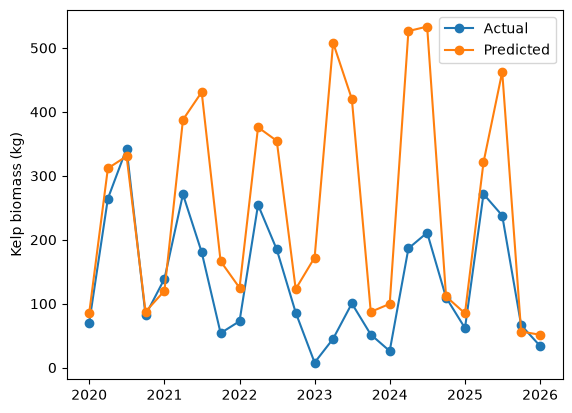

In [19]:
plt.plot(test.quarter, test.kelp_biomass, label="Actual", marker="o")
plt.plot(test.quarter, pred_kg, label="Predicted", marker="o")
plt.legend(); plt.ylabel("Kelp biomass (kg)"); plt.show()

## Random forrest for Long model

In [20]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [21]:
rf_model.fit(
    x_train,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [22]:
rf_pred = rf_model.predict(x_test)

In [23]:
print("Random Forest R2:", r2_score(y_test, rf_pred))

rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
print("Random Forest RMSE:", rmse)

Random Forest R2: -5.461019635330236
Random Forest RMSE: 238.41559882638416


----


# Looking at the light model 

## Linear model

In [24]:
x2 = light_model[
    ["avg_sst",
     "avg_pdo", 
     "avg_cuti",
     "avg_kdpar"]
]
y2 = light_model["kelp_biomass"]

In [25]:
light_model["q"] = light_model.quarter.dt.quarter
train2 = light_model[light_model.quarter < "2020-01-01"]
test2  = light_model[light_model.quarter >= "2020-01-01"]

cols = ["avg_sst", "avg_pdo", "avg_cuti", "avg_kdpar"]
x2_train, y2_train = train2[cols], train2["kelp_biomass"]
x2_test,  y2_test  = test2[cols],  test2["kelp_biomass"]

In [26]:
light_m = smf.ols(
    "np.log(kelp_biomass) ~ avg_sst + avg_pdo + avg_cuti + C(q) + avg_kdpar",
    data=train2
).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

In [27]:
print(light_m.summary())

                             OLS Regression Results                             
Dep. Variable:     np.log(kelp_biomass)   R-squared:                       0.690
Model:                              OLS   Adj. R-squared:                  0.599
Method:                   Least Squares   F-statistic:                     27.26
Date:                  Mon, 09 Nov 2026   Prob (F-statistic):           6.06e-10
Time:                          11:23:58   Log-Likelihood:                -29.452
No. Observations:                    32   AIC:                             74.90
Df Residuals:                        24   BIC:                             86.63
Df Model:                             7                                         
Covariance Type:                    HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     17.6769      3.703

In [28]:
pred_kg2 = np.exp(light_m.predict(test2))
rmse2 = np.sqrt(mean_squared_error(test2.kelp_biomass, pred_kg2))
r2_2 = r2_score(test2.kelp_biomass, pred_kg2)
print("RMSE:" ,rmse2)
print("R2:", r2_2)

RMSE: 129.10393576998163
R2: -0.8945701557905039


In [29]:
compare2 = pd.DataFrame({
    "quarter": test2.quarter,
    "observed": test2.kelp_biomass,
    "predicted": pred_kg2
})

print(compare2)

      quarter    observed   predicted
32 2020-01-01   69.960520   63.158980
33 2020-04-01  264.404434  171.557755
34 2020-07-01  342.731290  205.710496
35 2020-10-01   82.082960   40.324738
36 2021-01-01  138.857267   73.149481
37 2021-04-01  271.134726  294.121163
38 2021-07-01  180.554073  340.476059
39 2021-10-01   53.978529   75.569768
40 2022-01-01   72.580937   69.767301
41 2022-04-01  254.661505  158.224429
42 2022-07-01  184.800097  170.180062
43 2022-10-01   86.167638   67.823503
44 2023-01-01    7.899184  157.498912
45 2023-04-01   45.179641  454.783742
46 2023-07-01  100.385860  293.679659
47 2023-10-01   51.778461   54.528322
48 2024-01-01   25.986289   70.436882
49 2024-04-01  186.431066  443.543425
50 2024-07-01  211.108196  415.312375
51 2024-10-01  109.691788  101.877200
52 2025-01-01   61.866007  110.331330
53 2025-04-01  271.534719  203.957061
54 2025-07-01  237.894648  272.538760
55 2025-10-01   66.457176   31.132421
56 2026-01-01   33.916761   28.199976


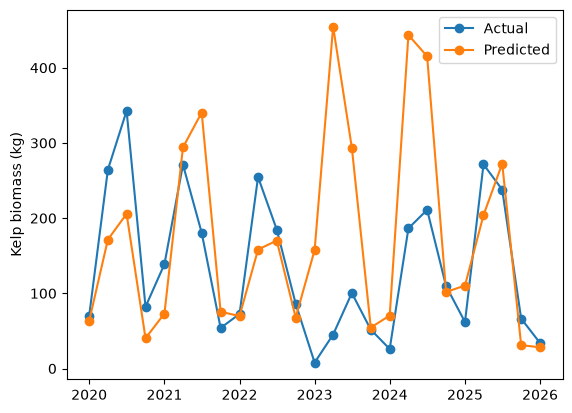

In [30]:
plt.plot(test2.quarter, test2.kelp_biomass, label="Actual", marker="o")
plt.plot(test2.quarter, pred_kg2, label="Predicted", marker="o")
plt.legend(); plt.ylabel("Kelp biomass (kg)"); plt.show()

## Random Forrest for Light model

In [31]:

random_2 =rrandom_2 = RandomForestRegressor(n_estimators=100, random_state=42).fit(x2_train, y2_train)

In [32]:
rf_pred2 = random_2.predict(x2_test)

In [33]:
print("Random Forest R2:", r2_score(y2_test, rf_pred2))
rmse3 = np.sqrt(mean_squared_error(y2_test, rf_pred2))
print("Random Forest RMSE:", rmse3)

Random Forest R2: -2.39662781249346
Random Forest RMSE: 172.8654164846363


---

## Waves and depth model

will be using PDO, sea surface temperatures, upwelling index, wave height(from a singular buoy), and depth of the ocean to predict future dates. 

Will be trying two different models than linear and random forest to see if we can predict kelp forecasting. 


- Cross validation with Ridge Regression

In [34]:
kelp_waves_depth

,lat,lat_band,lon,lon_band,elevation_m,quarter,kelp_biomass,kelp_area,sst_c,sst_quarter_lag,sst_anom_quarter_lag,avg_cuti,cuti_quarter_lag,avg_wave_height_m,max_wave_height_m,wave_max_lag,waves_quarter_lag,mean_pdo,pdo_quarter_lag
0,34.101043,682.0,-120.517883,-2411.0,-63.259403,2008-01-01,0.0,0.0,12.412837,NaN,NaN,0.739013,NaN,2.442391,8.84,NaN,NaN,-1.183333,-0.976667
1,34.101043,682.0,-120.517883,-2411.0,-63.259403,2008-04-01,4560.0,657.0,12.369462,12.412837,-0.510678,0.770022,0.739013,1.867674,4.70,8.84,2.442391,-1.546667,-1.183333
2,34.101043,682.0,-120.517883,-2411.0,-63.259403,2008-07-01,0.0,0.0,16.744123,12.369462,-0.619517,0.460989,0.770022,1.576353,3.19,4.70,1.867674,-1.313333,-1.546667
3,34.101043,682.0,-120.517883,-2411.0,-63.259403,2008-10-01,0.0,0.0,15.138735,16.744123,0.799257,0.345978,0.460989,2.002870,4.56,3.19,1.576353,-1.020000,-1.313333
4,34.101043,682.0,-120.517883,-2411.0,-63.259403,2009-01-01,0.0,0.0,13.050300,15.138735,-0.190096,0.243500,0.345978,2.005928,4.60,4.56,2.002870,-1.576667,-1.020000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8230423,34.048405,680.0,-119.727592,-2395.0,-6.319315,2024-07-01,0.0,0.0,NaN,NaN,NaN,0.593522,0.762791,1.609132,2.87,5.26,2.006216,-2.696667,-2.643333
8230424,34.048412,680.0,-119.727267,-2395.0,-6.319315,2023-04-01,0.0,0.0,NaN,NaN,NaN,0.815187,0.025644,1.756041,4.38,8.61,2.642912,-2.753333,-1.843333
8230425,34.048405,680.0,-119.727592,-2395.0,-6.319315,2023-04-01,0.0,0.0,NaN,NaN,NaN,0.815187,0.025644,1.756041,4.38,8.61,2.642912,-2.753333,-1.843333
8230426,34.048412,680.0,-119.727267,-2395.0,-6.319315,2014-01-01,0.0,0.0,NaN,NaN,NaN,-0.038111,-0.039272,2.177501,4.62,4.10,1.436298,0.140000,-0.800000


#### settig up predictors with kelp_biomass as my response variable

In [35]:
ocean_features = ['lat', 'lon','elevation_m', 'quarter', 'sst_c','sst_quarter_lag', 'mean_pdo', 'pdo_quarter_lag', 'avg_cuti','cuti_quarter_lag', 'avg_wave_height_m', 'waves_quarter_lag']
x_ocean = kelp_waves_depth[ocean_features]
y_ocean = kelp_waves_depth["kelp_biomass"]

#### Test Train split

Because this is a time series problem and I want to use cross validation so there are two options the time series split and the sliding window max train size, will attempt the time series split first

In [36]:
from sklearn.model_selection import TimeSeriesSplit
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge, RidgeClassifier, RidgeCV, RidgeClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge


In [37]:
ocean_features = ['lat', 'lon', 'elevation_m', 'sst_c', 'sst_quarter_lag',
                  'mean_pdo', 'pdo_quarter_lag', 'avg_cuti', 'cuti_quarter_lag',
                  'avg_wave_height_m', 'waves_quarter_lag']
df_kelp = kelp_waves_depth.dropna(subset=ocean_features + ['kelp_biomass']).copy()
df_kelp['q'] = df_kelp.quarter.dt.quarter 
X = pd.get_dummies(df_kelp[ocean_features + ['q']], columns=['q'], drop_first=True)
y = df_kelp['kelp_biomass']

is_train = df_kelp.quarter < pd.Timestamp('2020-01-01')
x_train_ocean, x_test_ocean = X[is_train], X[~is_train]
y_train_ocean, y_test_ocean = y[is_train], y[~is_train]


### Set up model

In [38]:
ridge_model = Ridge(alpha= 1.0)

In [39]:
ridge_model.fit(x_train_ocean, y_train_ocean)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [40]:
kelp_pred = ridge_model.predict(x_test_ocean)
display(pd.DataFrame({
    'observed_kelp_biomass': y_test_ocean,
    'predicted_kelp_biomass': kelp_pred, 
    'residual_kelp_biomass': y_test_ocean - kelp_pred
}))

,observed_kelp_biomass,predicted_kelp_biomass,residual_kelp_biomass
48,525.0,-874.257720,1399.257720
50,0.0,-558.982663,558.982663
51,433.0,-803.860324,1236.860324
52,0.0,-849.030557,849.030557
55,0.0,-818.709441,818.709441
...,...,...,...
8206521,0.0,599.754529,-599.754529
8206522,0.0,582.199418,-582.199418
8206523,0.0,117.549362,-117.549362
8206524,0.0,36.336615,-36.336615


My numbers are remaining too big need to find a way that it isn't overfitting

---


## OLS (Ordinary Least squares model) MODEL with heteroskedascity HAC
#### Heteroskedacity to use as explanatory analysis

Need to put some of the values in log functions because some of the higher numbers are overfitting especially in 2023-2025</br>
"np.log1p(kelp) ~ np.log1p(lag1) + C(q) + wave_h + temp_h"

Include the 16.5 degrees celcius threshold as that is the nutrient starvation threshold

In [41]:
kelp_hinges

,quarter,kelp_islands,kelp_mainland,kelp_pooled,sst_islands,sst_mainland,wave_max,wave_h
0,2012-01-01,113.039144,258.640447,148.322895,13.018307,13.089232,6.09,0.0
1,2013-01-01,168.554006,427.216387,231.256725,13.110245,13.159797,4.04,0.0
2,2013-10-01,124.296875,734.010756,272.095835,16.034954,16.024851,4.10,0.0
3,2015-07-01,348.318809,406.133118,362.346145,19.725055,19.723805,2.82,0.0
4,2018-10-01,9.680279,9.101146,9.539893,17.226894,17.437802,6.65,0.0
...,...,...,...,...,...,...,...,...
69,2017-04-01,267.438561,419.084270,304.203512,14.096264,13.838807,4.99,0.0
70,2017-10-01,70.393432,80.578984,72.862482,16.621289,16.653469,5.08,0.0
71,2018-07-01,229.963693,451.974519,283.797629,19.069302,19.262153,3.06,0.0
72,2019-10-01,48.323400,18.831460,41.174345,16.161483,16.422879,5.19,0.0


### setting up the data

In [42]:
kelp_hinges = con.execute("SELECT * FROM kelp_hinges ORDER BY quarter").df()

In [43]:
kelp_hinges["q"] = kelp_hinges.quarter.dt.quarter

for c in ["islands", "mainland", "pooled"]:
    kelp_hinges[f"log_kelp_biomass_{c}"] = np.log1p(kelp_hinges[f"kelp_{c}"]) # moves kelp to log function
    kelp_hinges[f"log_lag_kelp_biomass_{c}"] = kelp_hinges[f"log_kelp_biomass_{c}"].shift(1) # accounts for a  lag shift 

kelp_hinges["temp_h_islands"] = np.maximum(0, kelp_hinges["sst_islands"] - 16.5) # heat stress for islands
kelp_hinges["temp_h_mainland"] = np.maximum(0, kelp_hinges["sst_mainland"] - 16.5) # heat stress for mainland

#### set up my split

In [44]:
np.random.seed(42)
train_hinge = kelp_hinges[kelp_hinges.quarter < "2020-01-01"]
test_hinge  = kelp_hinges[kelp_hinges.quarter >= "2020-01-01"]

In [45]:


isl = smf.ols(
    "log_kelp_biomass_islands ~ log_lag_kelp_biomass_islands + C(q) + wave_h + temp_h_islands",
    data=kelp_hinges).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

print(isl.summary())


                               OLS Regression Results                               
Dep. Variable:     log_kelp_biomass_islands   R-squared:                       0.703
Model:                                  OLS   Adj. R-squared:                  0.676
Method:                       Least Squares   F-statistic:                     81.62
Date:                      Mon, 09 Nov 2026   Prob (F-statistic):           1.36e-28
Time:                              11:24:03   Log-Likelihood:                -63.453
No. Observations:                        73   AIC:                             140.9
Df Residuals:                            66   BIC:                             156.9
Df Model:                                 6                                         
Covariance Type:                        HAC                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------

In [46]:
main = smf.ols(
    "log_kelp_biomass_mainland ~ log_lag_kelp_biomass_mainland + C(q) + wave_h + temp_h_mainland",
    data=kelp_hinges).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(main.summary())

                                OLS Regression Results                               
Dep. Variable:     log_kelp_biomass_mainland   R-squared:                       0.564
Model:                                   OLS   Adj. R-squared:                  0.524
Method:                        Least Squares   F-statistic:                     47.66
Date:                       Mon, 09 Nov 2026   Prob (F-statistic):           4.07e-22
Time:                               11:24:03   Log-Likelihood:                -84.750
No. Observations:                         73   AIC:                             183.5
Df Residuals:                             66   BIC:                             199.5
Df Model:                                  6                                         
Covariance Type:                         HAC                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------

In [47]:
pooled = smf.ols( "log_kelp_biomass_pooled ~ log_lag_kelp_biomass_mainland + C(q) + wave_h + temp_h_mainland",
    data=kelp_hinges).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(pooled.summary())

                               OLS Regression Results                              
Dep. Variable:     log_kelp_biomass_pooled   R-squared:                       0.581
Model:                                 OLS   Adj. R-squared:                  0.543
Method:                      Least Squares   F-statistic:                     103.8
Date:                     Mon, 09 Nov 2026   Prob (F-statistic):           1.20e-31
Time:                             11:24:03   Log-Likelihood:                -72.476
No. Observations:                       73   AIC:                             159.0
Df Residuals:                           66   BIC:                             175.0
Df Model:                                6                                         
Covariance Type:                       HAC                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------

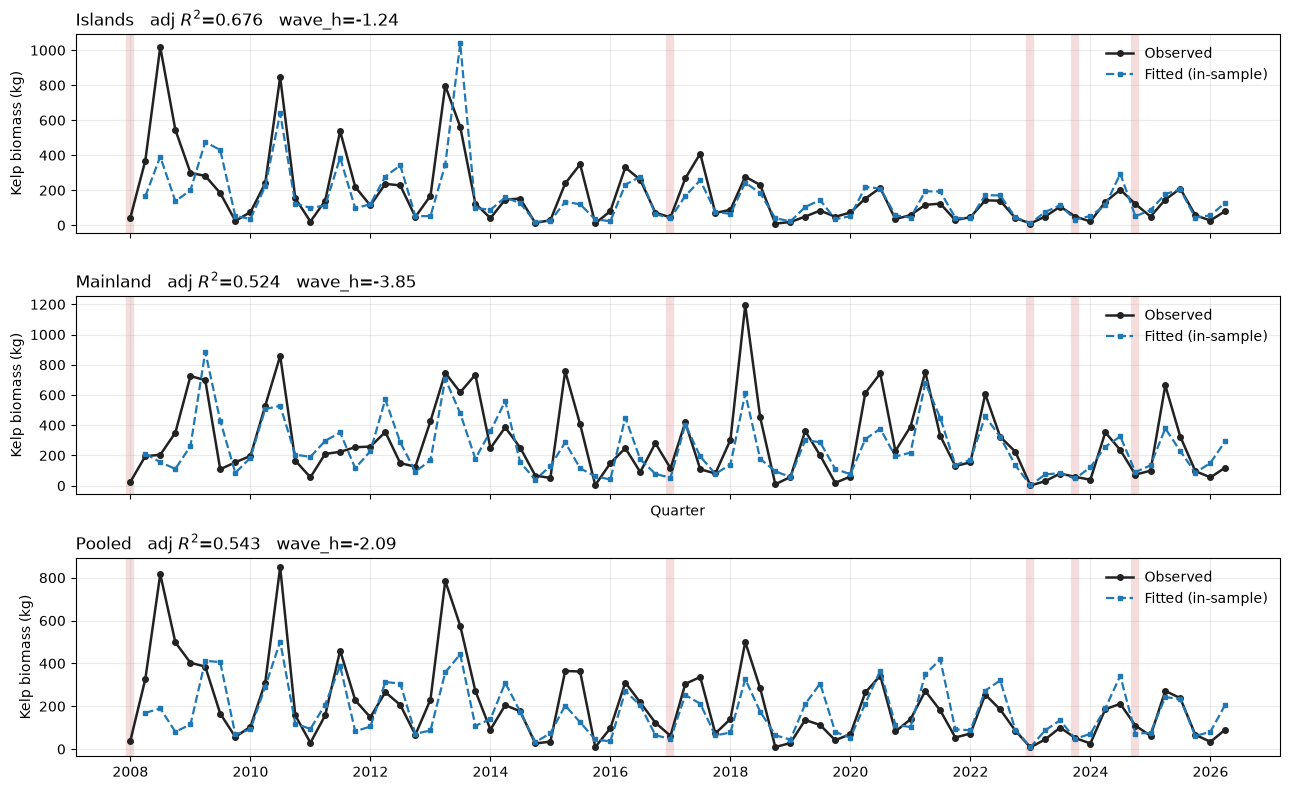

In [48]:
import matplotlib.pyplot as plt

kh = kelp_hinges.copy()
kh["fit_islands"]  = np.expm1(isl.fittedvalues)
kh["fit_mainland"] = np.expm1(main.fittedvalues)
kh["fit_pooled"] = np.expm1(pooled.fittedvalues)
storms = kh.loc[kh.wave_h > 0, "quarter"]

fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for a, coast, r in [(ax[0], "islands", isl), (ax[1], "mainland", main), [ax[2], "pooled", pooled]]:
    for s in storms:
        a.axvline(s, color="#c44", alpha=.18, lw=6, zorder=0)
    a.plot(kh.quarter, kh[f"kelp_{coast}"], "o-", color="#222", lw=1.8, ms=4,
           label="Observed")
    a.plot(kh.quarter, kh[f"fit_{coast}"], "s--", lw=1.6, ms=3.5,
           label="Fitted (in-sample)")
    a.set_title(f"{coast.capitalize()}   adj $R^2$={r.rsquared_adj:.3f}   "
                f"wave_h={r.params['wave_h']:.2f}", loc="left")
    a.set_ylabel("Kelp biomass (kg)")
    a.legend(frameon=False)
    a.grid(alpha=.25)
ax[1].set_xlabel("Quarter")
plt.tight_layout()


## predictive model

will put the forecasting for 2018, will use hst the kelp and the quarter of the year because it accounts for seaonality

In [49]:
kelp_hinges = kelp_hinges.sort_values("quarter").reset_index(drop=True)
START = int(np.where(kelp_hinges.quarter == "2018-01-01")[0][0])
print(START, len(kelp_hinges))          

rows = [] # creates an empty list to store the results
for i in range(START, len(kelp_hinges)):
    train_pred = kelp_hinges.iloc[:i].dropna(# creates a training set that includes all data up to the current index
        subset=["log_lag_kelp_biomass_islands", "log_lag_kelp_biomass_mainland", "log_lag_kelp_biomass_pooled"]) 
    row = kelp_hinges.iloc[[i]] # double brackets remain a data frame


40 74


In [61]:
df_split = con.sql("""
             SELECT round(lat,1) AS lat_bin,
       count(DISTINCT (lat,lon)) AS pixels,
       round(avg(kelp_biomass),1) AS mean_kelp,
       round(avg(elevation_m),1) AS mean_depth
FROM kelp_waves_depth
GROUP BY 1 ORDER BY 1
             """).df()
df_split

,lat_bin,pixels,mean_kelp,mean_depth
0,33.9,14129,143.7,-13.9
1,34.0,61008,192.5,-12.3
2,34.1,9124,113.5,-13.6
3,34.3,945,126.5,-7.3
4,34.4,16596,288.7,-11.3
5,34.5,9420,307.0,-10.4


lat 34.2 is where we will split between mainland and islands. If its smaller than 34.2 it is the mainland, if its greater it will be lat is islands. 

islands  (lat < 34.2):  14,129 + 61,008 + 9,124 =  84,261 pixels
mainland (lat ≥ 34.2):     945 + 16,596 + 9,420 =  26,961 pixels
                                          total = 111,222

84,261 / 111,222 = 0.7576  →  0.758
26,961 / 111,222 = 0.2424  →  0.242

### create the models for islands, mainland, and combined (pooled)
#### includes lag of prior kelp + what quarter * temp + wave

In [51]:
p_island = np.expm1(smf.ols("log_kelp_biomass_islands ~ log_lag_kelp_biomass_islands + C(q) + wave_h + temp_h_islands", data =train_pred).fit().predict(row).iloc[0])

In [52]:
p_mainland = np.expm1(smf.ols("log_kelp_biomass_islands ~ log_lag_kelp_biomass_mainland + C(q) + wave_h + temp_h_mainland", data =train_pred).fit().predict(row).iloc[0])

In [53]:
p_pooled = np.expm1(smf.ols("log_kelp_biomass_pooled ~ log_lag_kelp_biomass_pooled + C(q) + wave_h + temp_h_mainland", data =train_pred).fit().predict(row).iloc[0])

appending the data

In [54]:
rows.append(dict(
    quarter=kelp_hinges.quarter.iloc[i],
    actual = kelp_hinges.kelp_pooled.iloc[i],
    split = p_island*0.758 + p_mainland*0.242,
    pred_pool = p_pooled, 
    pred_island = p_island,
    pred_mainland = p_mainland
))

In [55]:
pp = pd.DataFrame(rows)
for col in ["split", "pred_pool", "pred_island", "pred_mainland"]:
    rmse = np.sqrt(np.mean((pp.actual - pp[col])**2))
    bias = np.mean(pp[col]-pp.actual)
    print(f"{col} RMSE: {rmse:.3f}")

split RMSE: 49.628
pred_pool RMSE: 89.584
pred_island RMSE: 41.496
pred_mainland RMSE: 75.099


In [56]:
print(pp.dtypes)
print(pp.head(3))

quarter          datetime64[us]
actual                  float64
split                   float64
pred_pool               float64
pred_island             float64
pred_mainland           float64
dtype: object
     quarter     actual       split   pred_pool  pred_island  pred_mainland
0 2026-04-01  90.836359  140.464412  180.420517   132.332604     165.935114


--- 

"np.log1p(kelp) ~ np.log1p(lag1) + C(q)"

Let's see if putting less has a better result by means of excluding water temp and waves

In [57]:
kelp_hinges = kelp_hinges.sort_values("quarter").reset_index(drop=True)
START = int(np.where(kelp_hinges.quarter == "2018-01-01")[0][0])

rows = []
for i in range(START, len(kelp_hinges)):
    tr  = kelp_hinges.iloc[:i].dropna(subset=["log_lag_kelp_biomass_islands",
                                              "log_lag_kelp_biomass_mainland",
                                              "log_lag_kelp_biomass_pooled"])
    row = kelp_hinges.iloc[[i]]

    p_isl  = np.expm1(smf.ols("log_kelp_biomass_islands ~ log_lag_kelp_biomass_islands + C(q)",
                              data=tr).fit().predict(row).iloc[0])
    p_main = np.expm1(smf.ols("log_kelp_biomass_mainland ~ log_lag_kelp_biomass_mainland + C(q)",
                              data=tr).fit().predict(row).iloc[0])
    p_pool = np.expm1(smf.ols("log_kelp_biomass_pooled ~ log_lag_kelp_biomass_pooled + C(q)",
                              data=tr).fit().predict(row).iloc[0])

    rows.append(dict(quarter   = kelp_hinges.quarter.iloc[i],
                     actual    = kelp_hinges.kelp_pooled.iloc[i],
                     split     = p_isl*0.758 + p_main*0.242,
                     pred_pool = p_pool))

pp = pd.DataFrame(rows)
print(len(pp), "forecasts")
for col in ["split", "pred_pool"]:
    print(f"{col:10s} RMSE={np.sqrt(np.mean((pp.actual-pp[col])**2)):6.1f}  "
          f"bias={np.mean(pp[col]-pp.actual):+6.1f}")

34 forecasts
split      RMSE=  51.9  bias=  +8.1
pred_pool  RMSE=  63.3  bias= +23.3


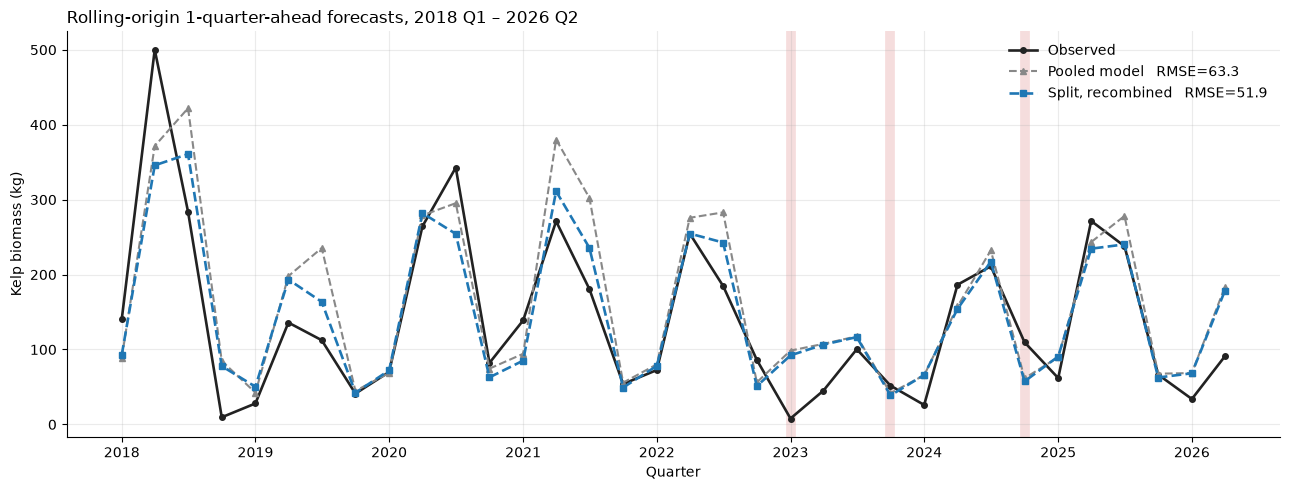

In [58]:
storms = kelp_hinges.loc[kelp_hinges.wave_h > 0, "quarter"]
rmse = lambda c: np.sqrt(np.mean((pp.actual - pp[c])**2))

fig, ax = plt.subplots(figsize=(13, 5))
for s in storms:
    if s >= pp.quarter.min():
        ax.axvline(s, color="#c44", alpha=.18, lw=7, zorder=0)

ax.plot(pp.quarter, pp.actual,    "o-",  color="#222",    lw=1.9, ms=4,
        label="Observed")
ax.plot(pp.quarter, pp.pred_pool, "^--", color="#888",    lw=1.5, ms=4,
        label=f"Pooled model   RMSE={rmse('pred_pool'):.1f}")
ax.plot(pp.quarter, pp.split,     "s--", color="#1f77b4", lw=1.9, ms=4,
        label=f"Split, recombined   RMSE={rmse('split'):.1f}")

ax.set_title("Rolling-origin 1-quarter-ahead forecasts, 2018 Q1 – 2026 Q2", loc="left")
ax.set_ylabel("Kelp biomass (kg)")
ax.set_xlabel("Quarter")
ax.legend(frameon=False)
ax.grid(alpha=.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

---


In [59]:
#con.close()